### 1. Initial preparation, importing libraries and dataset

In [1]:
#data handling base
import pandas as pd
import numpy as np

#visualization
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#import dataset from csv file
df = pd.read_csv('twcs.csv')

In [3]:
#column info
print(df.isna().sum())
print('*'*40)
print(df.info())

tweet_id                         0
author_id                        0
inbound                          0
created_at                       0
text                             0
response_tweet_id          1040629
in_response_to_tweet_id     794335
dtype: int64
****************************************
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2811774 entries, 0 to 2811773
Data columns (total 7 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   tweet_id                 int64  
 1   author_id                object 
 2   inbound                  bool   
 3   created_at               object 
 4   text                     object 
 5   response_tweet_id        object 
 6   in_response_to_tweet_id  float64
dtypes: bool(1), float64(1), int64(1), object(4)
memory usage: 131.4+ MB
None


### 2. Data preparation and cleaning

In [4]:
nonthreads = df[df['response_tweet_id'].isna() & df['in_response_to_tweet_id'].isna()]
nonthreads

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id


In [5]:
#thread root:
def get_thread_root(tweet_id, parent_map):
    visited = set()
    while tweet_id in parent_map and tweet_id not in visited:
        visited.add(tweet_id)
        tweet_id = parent_map[tweet_id]
    return tweet_id

In [44]:
#find root tweets (inbound with no parent)
twroot = df[(df['inbound'] == True) & (df['in_response_to_tweet_id'].isna())]['tweet_id']

#get sample before applying to whole dataset, since 3 mil rows is long to compute.
sampled_roots = twroot.sample(n=100000, random_state=42)
#Instead of sampling dataset directly, I sampled roots, otherwise threads would be truncated

# pull all tweets belonging to those threads
parent_map = df.dropna(subset=['in_response_to_tweet_id']).set_index('tweet_id')['in_response_to_tweet_id'].to_dict()

df['thread_root'] = df['tweet_id'].apply(lambda x: get_thread_root(x, parent_map))

df['is_root'] = df['in_response_to_tweet_id'].isna()
df['is_end'] = df['response_tweet_id'].isna()

df_sample = df[df['thread_root'].isin(sampled_roots)].copy()
df_sample.head(10)

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end
32,38,VerizonSupport,False,Tue Oct 31 22:13:30 +0000 2017,@115720 Have your friend message us.\n^ACM,NaN,39.00000,39.00000,False,True
33,39,115720,True,Tue Oct 31 22:12:16 +0000 2017,@VerizonSupport My friend is without internet ...,38,NaN,39.00000,True,False
63,70,ChipotleTweets,False,Tue Oct 31 22:13:29 +0000 2017,@115730 Hopefully we'll get there at some poin...,NaN,71.00000,71.00000,False,True
64,71,115730,True,Tue Oct 31 22:03:06 +0000 2017,hey @ChipotleTweets wanna come to Mammoth. I'l...,"70,72",NaN,71.00000,True,False
76,154,ChipotleTweets,False,Tue Oct 31 22:09:00 +0000 2017,@115735 I'm so glad we could help. Who did you...,NaN,155.00000,156.00000,False,True
77,155,115735,True,Tue Oct 31 22:00:46 +0000 2017,@ChipotleTweets Thank you @ChipotleTweets for ...,154,156.00000,156.00000,False,False
78,156,115735,True,Mon Oct 23 03:19:06 +0000 2017,So frustrated with @ChipotleTweets 😡 Ordered d...,"155,157",NaN,156.00000,True,False
91,170,ChipotleTweets,False,Tue Oct 31 22:01:00 +0000 2017,@115741 Noted 😊 -Becky,NaN,171.00000,175.00000,False,True
92,171,115741,True,Tue Oct 31 21:57:23 +0000 2017,@ChipotleTweets Also I got the onesie at targe...,170,172.00000,175.00000,False,False
93,172,115741,True,Tue Oct 31 21:57:08 +0000 2017,@ChipotleTweets Thanks Becky! Just feeling sor...,"173,171",174.00000,175.00000,False,False


In [34]:
# All tweet IDs present in the dataset
parent_ids_in_data = set(df['tweet_id'])

# All parent references (drop NaN roots)
orphaned = df['in_response_to_tweet_id'].dropna()

# Boolean mask: True if parent is missing
mask = ~orphaned.isin(parent_ids_in_data)

orphan_count = mask.sum()
print(f'Orphaned tweets: {orphan_count} ({orphan_count/len(df)*100:.1f}%)')

# Create a dataframe of orphaned replies
df_orphans = df.loc[df['in_response_to_tweet_id'].isin(orphaned[mask])]
df_orphans.head()


Orphaned tweets: 3862 (0.1%)


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end
138,222,115760,True,Tue Oct 31 19:05:30 +0000 2017,@108162 @115761 @ATVIAssist tried that there w...,221,223.00000,223.00000,False,False
1035,1621,AzureSupport,False,Tue Oct 31 22:11:47 +0000 2017,@116051 Sorry to hear your having trouble. Cou...,1620,1622.00000,1622.00000,False,False
2817,3745,AmazonHelp,False,Tue Oct 31 22:36:29 +0000 2017,"@116616 David, te recomendamos no compartir in...",3744,3746.00000,3746.00000,False,False
2848,3777,116625,True,Tue Oct 31 22:53:05 +0000 2017,@AppleSupport I've also forced the app to clos...,3775,3779.00000,3779.00000,False,False
4082,5530,Ask_Spectrum,False,Tue Oct 31 23:08:39 +0000 2017,@117003 Please remove that from public. I have...,5529,5531.00000,5531.00000,False,False


In [46]:
orphan_thr = df_orphans['thread_root']
df = df.loc[~df['thread_root'].isin(orphan_thr)]
df[(df['thread_root'] ==1622)]

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end


In [7]:
#making all text lowercase
df_sample["text"] = df_sample["text"].str.lower()

In [8]:
df_sample['created_at'] = pd.to_datetime(df_sample['created_at'], format='%a %b %d %H:%M:%S %z %Y', errors='coerce')
df_sample = df_sample.sort_values(['thread_root', 'created_at'])
df_sample['turn_index'] = df_sample.groupby('thread_root').cumcount()
df_sample.head(5)

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,turn_index
33,39,115720,True,2017-10-31 22:12:16+00:00,@verizonsupport my friend is without internet ...,38,NaN,39.0,True,False,0
32,38,VerizonSupport,False,2017-10-31 22:13:30+00:00,@115720 have your friend message us.\n^acm,NaN,39.0,39.0,False,True,1
64,71,115730,True,2017-10-31 22:03:06+00:00,hey @chipotletweets wanna come to mammoth. i'l...,"70,72",NaN,71.0,True,False,0
63,70,ChipotleTweets,False,2017-10-31 22:13:29+00:00,@115730 hopefully we'll get there at some poin...,NaN,71.0,71.0,False,True,1
78,156,115735,True,2017-10-23 03:19:06+00:00,so frustrated with @chipotletweets 😡 ordered d...,"155,157",NaN,156.0,True,False,0


### 3. Descriptive analysis

In [10]:
# pd.set_option('display.max_colwidth', 100)
# df_sample.style.set_properties(**{'text-align': 'left'})
# print(df_sample["text"].head(30))
# pd.set_option('display.max_colwidth', 30)

In [11]:
#comparing the percentage of root and end tweets in sample vs full dataset
nullratio = df_sample['in_response_to_tweet_id'].isna().sum() / df_sample.shape[0] * 100
print('sample root tweet percentage = ', nullratio,'%')

nullratio1 = df['in_response_to_tweet_id'].isna().sum() / df.shape[0] * 100
print('root tweet percentage        = ',nullratio1,'%')

nullratio2 = df_sample['response_tweet_id'].isna().sum() / df_sample.shape[0] * 100
print('sample end tweet percentage  = ',nullratio2,'%')

nullratio3 = df['response_tweet_id'].isna().sum() / df.shape[0] * 100
print('end tweet percentage         = ',nullratio3,'%')

sample root tweet percentage =  29.082195007750407 %
root tweet percentage        =  28.250314570089913 %
sample end tweet percentage  =  37.13679973709696 %
end tweet percentage         =  37.009695658328155 %


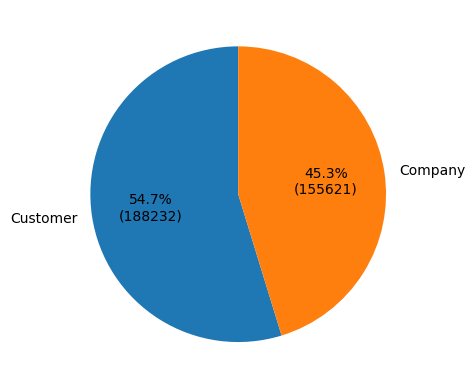

In [12]:
def make_autopct(values):
    def my_autopct(pct):
        total = sum(values)
        val = int(round(pct * total / 100.0))
        return f'{pct:.1f}%\n({val:d})'
    return my_autopct

inbound = df_sample['inbound'].value_counts()
plt.pie(x=inbound, labels=['Customer', 'Company'], autopct=make_autopct(inbound), startangle = 90)
plt.show()

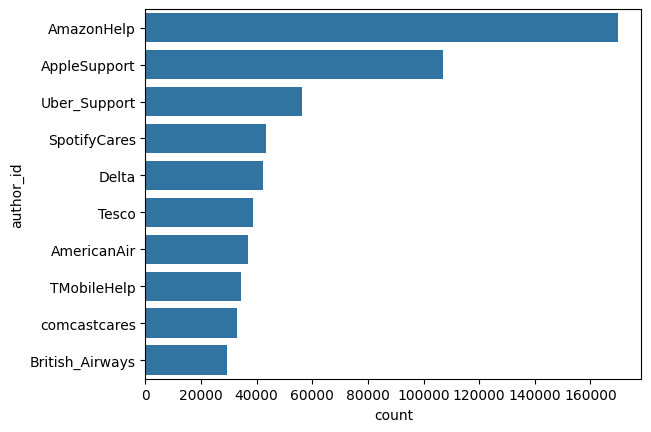

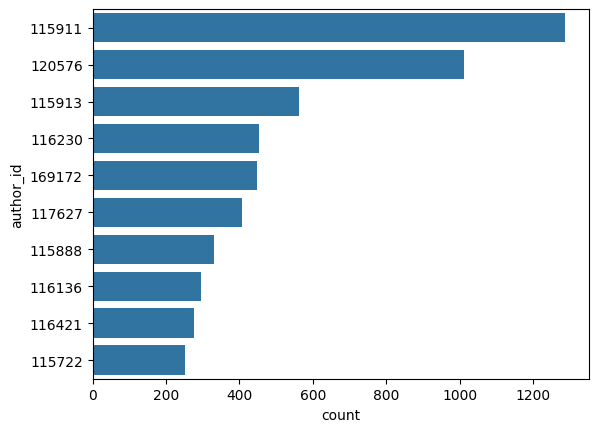

In [13]:
#filter only companies
companies = df[(df['inbound'] == False)]

#top 10 by count
order = companies['author_id'].value_counts().iloc[:10].index

#visualization
sns.countplot(companies['author_id'], order = order)
plt.show()

companies.head(5)

users = df[(df['inbound'] == True)]

order1 = users['author_id'].value_counts().iloc[:10].index

sns.countplot(users['author_id'], order = order1)
plt.show()

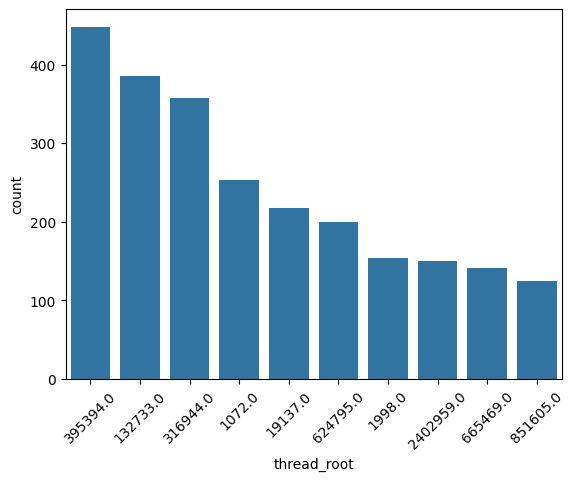

In [14]:
order2 = df_sample['thread_root'].value_counts().iloc[:10].index
sns.countplot(x = 'thread_root', data = df_sample, order = order2)
plt.xticks(rotation=45)
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

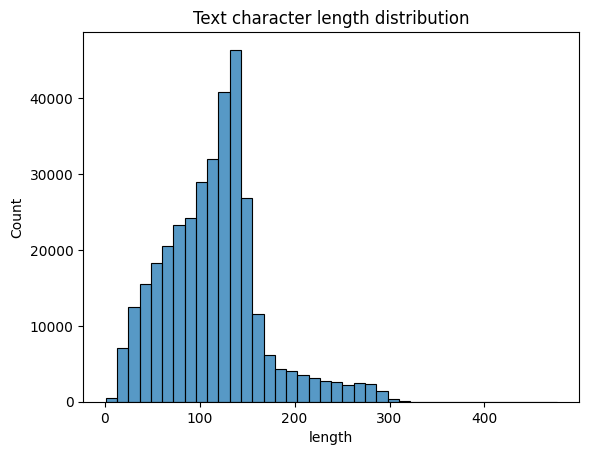

In [30]:
df_sample['chr_length'] = df_sample['text'].str.len()
sns.histplot(df_sample['chr_length'], bins = 40)

plt.title('Text character length distribution')
plt.xlabel('length')
plt.show

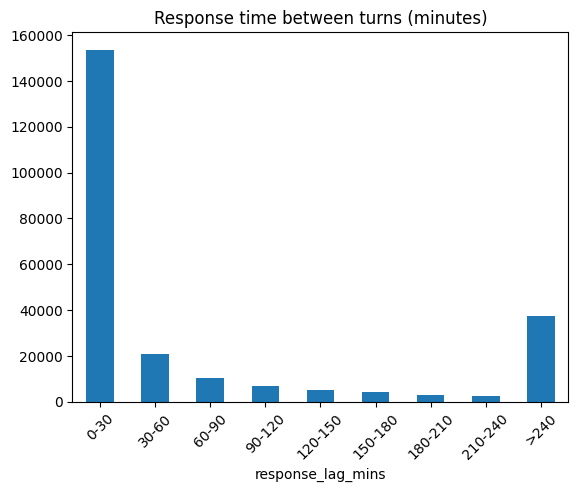

In [16]:
df_sample['response_lag_mins'] = df_sample.groupby('thread_root')['created_at'].diff().dt.total_seconds() / 60
lag = df_sample['response_lag_mins'].dropna()

bins = [0, 30, 60, 90, 120, 150, 180, 210, 240, np.inf]
labels = ['0-30', '30-60', '60-90', '90-120', '120-150', '150-180', '180-210', '210-240', '>240']

lag_binned = pd.cut(lag, bins=bins, labels=labels, right=False)
counts = lag_binned.value_counts().reindex(labels)
counts.plot(kind='bar')
plt.title('Response time between turns (minutes)')
plt.xticks(rotation=45)
plt.show()

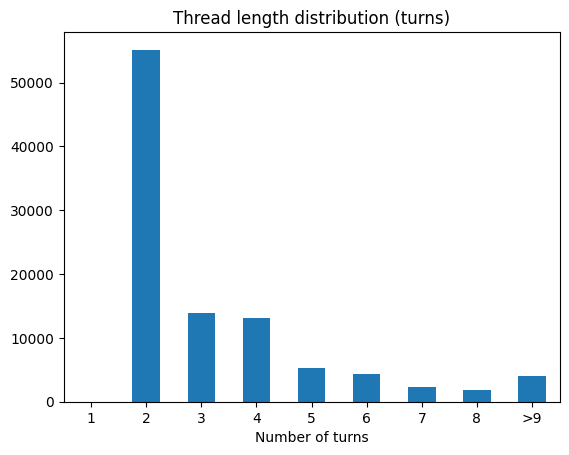

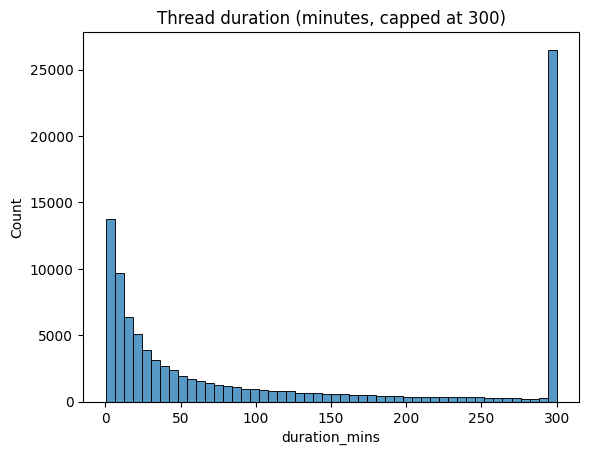

In [31]:
thread_stats = df_sample.groupby('thread_root').agg(
    turn_count=('tweet_id', 'count'),
    duration_mins=('created_at', lambda x: (x.max() - x.min()).total_seconds() / 60)
).reset_index()


bins1 = [1, 2, 3, 4, 5, 6, 7, 8, 9, np.inf]
labels1 = ['1', '2', '3', '4', '5', '6', '7', '8', '>9']
thr = thread_stats['turn_count']


thr_bin = pd.cut(thr, bins=bins1, labels=labels1, right=False)
counts = thr_bin.value_counts().reindex(labels1)
counts.plot(kind='bar')

plt.title('Thread length distribution (turns)')
plt.xlabel('Number of turns')
plt.xticks(rotation = 0)
plt.show()

sns.histplot(thread_stats['duration_mins'].clip(upper=300), bins=50)
plt.title('Thread duration (minutes, capped at 300)')
plt.show()

In [18]:
pd.set_option('display.float_format', lambda x: '%.5f' % x)
print(thread_stats.describe())


        thread_root   turn_count  duration_mins
count  100000.00000 100000.00000   100000.00000
mean  1571294.51914      3.43853     1921.62633
std    852132.00270      3.97524    34261.44341
min        39.00000      2.00000        0.16667
25%    836267.00000      2.00000       13.51667
50%   1635187.50000      2.00000       58.35000
75%   2296702.25000      4.00000      340.53333
max   2987946.00000    448.00000  3385525.48333


In [19]:
thre = thread_stats[(thread_stats['duration_mins'] > 2880)]
df_sample2 = df_sample[df_sample['thread_root'].isin(thre['thread_root'])]
df_sample2

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,turn_index,chr_length,response_lag_mins
78,156,115735,True,2017-10-23 03:19:06+00:00,so frustrated with @chipotletweets 😡 ordered d...,"155,157",NaN,156.00000,True,False,0,134,NaN
927485,157,ChipotleTweets,False,2017-10-23 03:55:00+00:00,@115735 that's concerning. please share this w...,NaN,156.00000,156.00000,False,True,1,81,35.90000
77,155,115735,True,2017-10-31 22:00:46+00:00,@chipotletweets thank you @chipotletweets for ...,154,156.00000,156.00000,False,False,2,111,12605.76667
76,154,ChipotleTweets,False,2017-10-31 22:09:00+00:00,@115735 i'm so glad we could help. who did you...,NaN,155.00000,156.00000,False,True,3,94,8.23333
180,253,115768,True,2017-10-29 21:02:31+00:00,@115769 whats going on with your app. its tota...,251,NaN,253.00000,True,False,0,154,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2811241,2987425,AirAsiaSupport,False,2017-11-30 07:44:02+00:00,"@823716 sorry for the delay, simon. may we hav...",2987426,2987427.00000,2987427.00000,False,False,1,106,3354.23333
2811242,2987426,823717,True,2017-11-30 07:47:01+00:00,"@airasiasupport @823716 hi @airasiasupport, co...",NaN,2987425.00000,2987427.00000,False,True,2,80,2.98333
2811466,2987648,823773,True,2017-08-18 22:44:11+00:00,@southwestair you should be proud of rachel on...,2987646,NaN,2987648.00000,True,False,0,142,NaN
2811464,2987646,SouthwestAir,False,2017-08-18 23:16:32+00:00,@823773 our apologies if our customer service ...,2987647,2987648.00000,2987648.00000,False,False,1,129,32.35000


In [20]:
thre['duration_mins'].value_counts().sort_index(ascending=False)

duration_mins
3385525.48333    1
3295505.53333    1
2870714.93333    1
2665719.91667    1
2129709.73333    1
                ..
2882.48333       1
2882.20000       1
2882.01667       1
2881.40000       1
2881.21667       1
Name: count, Length: 6134, dtype: int64

In [21]:
df_sample2.describe()

,tweet_id,in_response_to_tweet_id,thread_root,turn_index,chr_length,response_lag_mins
count,41882.00000,35701.00000,41882.00000,41882.00000,41882.00000,35701.00000
mean,1213051.03333,1126620.02821,1087657.51750,14.89088,114.83332,4704.33790
std,854162.32631,840690.66819,838790.61612,42.81417,52.68725,55613.39638
min,154.00000,155.00000,156.00000,0.00000,6.00000,0.00000
25%,419361.25000,368311.00000,319453.00000,1.00000,78.00000,4.75000
50%,1085831.50000,976716.00000,921386.00000,3.00000,117.00000,44.31667
75%,1931842.75000,1764253.00000,1715672.25000,9.00000,140.00000,1198.93333
max,2987648.00000,2987648.00000,2987648.00000,447.00000,476.00000,3385497.86667


In [22]:
df_sample.describe()

,tweet_id,in_response_to_tweet_id,thread_root,turn_index,chr_length,response_lag_mins
count,343853.00000,243853.00000,343853.00000,343853.00000,343853.00000,243853.00000
mean,1510952.12681,1473175.58286,1491226.28451,3.51711,114.22204,788.02653
std,861204.35914,866054.08259,865699.97248,15.87244,52.03632,21342.55090
min,38.00000,39.00000,39.00000,0.00000,1.00000,0.00000
25%,769522.00000,727834.00000,740727.00000,0.00000,79.00000,3.15000
50%,1520118.00000,1456668.00000,1492938.00000,1.00000,116.00000,13.01667
75%,2256426.00000,2228648.00000,2241695.00000,3.00000,140.00000,83.30000
max,2987946.00000,2987946.00000,2987946.00000,447.00000,476.00000,3385497.86667


In [25]:
with pd.option_context("display.max_rows", 1000):
    display(df_sample[df_sample['thread_root'] == 15807])

,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,thread_root,is_root,is_end,turn_index,chr_length,response_lag_mins


In [26]:
author_counts = (
    df.groupby('thread_root')['author_id']
    .nunique()
    .reset_index()
    .rename(columns={'author_id': 'n_distinct_authors'})
)

# Flag multi-party threads
author_counts['multi_party'] = author_counts['n_distinct_authors'] > 2

print(author_counts['n_distinct_authors'].value_counts().sort_index())
print(f"\nMulti-party threads: {author_counts['multi_party'].sum()}")

n_distinct_authors
1          86
2      740902
3       44499
4        6971
5        2103
        ...  
231         1
283         2
337         1
620         1
973         1
Name: count, Length: 120, dtype: int64

Multi-party threads: 57024


In [27]:
thread_stats.describe()

,thread_root,turn_count,duration_mins
count,100000.00000,100000.00000,100000.00000
mean,1571294.51914,3.43853,1921.62633
std,852132.00270,3.97524,34261.44341
min,39.00000,2.00000,0.16667
25%,836267.00000,2.00000,13.51667
50%,1635187.50000,2.00000,58.35000
75%,2296702.25000,4.00000,340.53333
max,2987946.00000,448.00000,3385525.48333
